# Sonar Signal Classification: Advanced Workflow

A reproducible, leakage-aware comparison and evaluation of models that distinguish **mines** from **rocks** using 60 sonar-return measurements.

**Learning goals:** establish a baseline, select hyperparameters with stratified cross-validation, evaluate once on a held-out test set, inspect ranking and threshold behavior, and interpret feature influence.

> The dataset is small (208 rows), so all reported test metrics have substantial sampling uncertainty. Treat them as an estimate, not a guarantee of field performance.

In [ ]:
# Dependencies (run once if needed)
# %pip install -q numpy pandas matplotlib seaborn scikit-learn

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, make_scorer,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
    RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 12)


## 1. Load and validate the data

The UCI-style file contains 60 numeric attributes and a final label (`R` or `M`). The path lookup supports running from either the project root or this notebook folder.

In [2]:
candidates = [Path("sonar_data.csv"), Path("solar_classification.ipynb/sonar_data.csv")]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Could not find sonar_data.csv in the current or notebook directory.")

raw = pd.read_csv(data_path, header=None)
assert raw.shape[1] == 61, f"Expected 60 features plus target, got {raw.shape[1]} columns"
assert raw.iloc[:, -1].isin(["R", "M"]).all(), "Unexpected target labels found"

feature_names = [f"band_{i:02d}" for i in range(1, 61)]
X = raw.iloc[:, :-1].astype(float).set_axis(feature_names, axis=1)
y = raw.iloc[:, -1].map({"R": 0, "M": 1}).rename("target")
class_names = {0: "Rock", 1: "Mine"}

print(f"Loaded {len(X)} observations × {X.shape[1]} features from {data_path}")
class_summary = y.map(class_names).value_counts().rename_axis("class").to_frame("count")
class_summary["fraction"] = class_summary["count"] / len(y)
display(class_summary)
display(X.describe().T.head(10))
print("Missing values:", int(X.isna().sum().sum()), "| Duplicate rows:", int(raw.duplicated().sum()))


Loaded 208 observations × 60 features from sonar_data.csv


,count,fraction
class,,
Mine,111,0.533654
Rock,97,0.466346


,count,mean,std,min,25%,50%,75%,max
band_01,208.0,0.029164,0.022991,0.0015,0.013350,0.02280,0.035550,0.1371
band_02,208.0,0.038437,0.032960,0.0006,0.016450,0.03080,0.047950,0.2339
band_03,208.0,0.043832,0.038428,0.0015,0.018950,0.03430,0.057950,0.3059
band_04,208.0,0.053892,0.046528,0.0058,0.024375,0.04405,0.064500,0.4264
band_05,208.0,0.075202,0.055552,0.0067,0.038050,0.06250,0.100275,0.4010
band_06,208.0,0.104570,0.059105,0.0102,0.067025,0.09215,0.134125,0.3823
band_07,208.0,0.121747,0.061788,0.0033,0.080900,0.10695,0.154000,0.3729
band_08,208.0,0.134799,0.085152,0.0055,0.080425,0.11210,0.169600,0.4590
band_09,208.0,0.178003,0.118387,0.0075,0.097025,0.15225,0.233425,0.6828
band_10,208.0,0.208259,0.134416,0.0113,0.111275,0.18240,0.268700,0.7106


Missing values: 0 | Duplicate rows: 0


## 2. Exploratory analysis

Check class balance, feature distributions, and correlation structure. These plots are descriptive; model selection happens only after the train/test split.

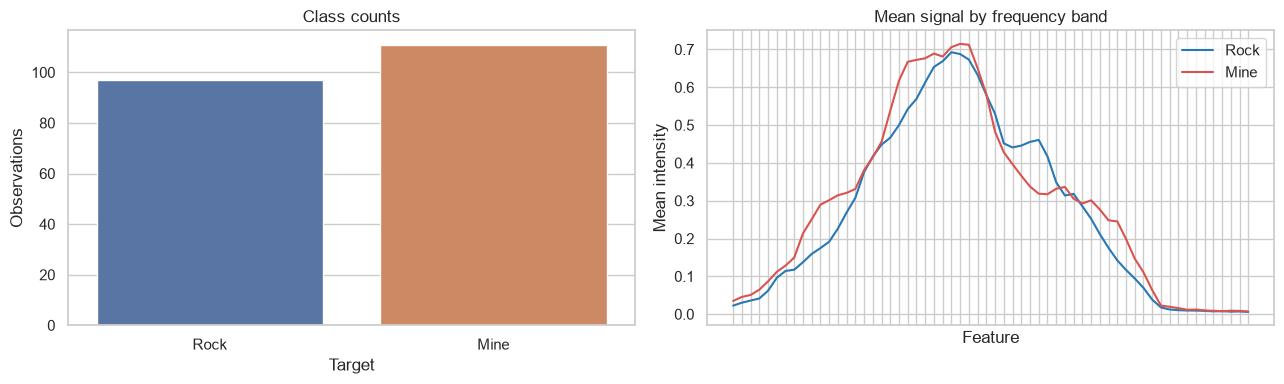

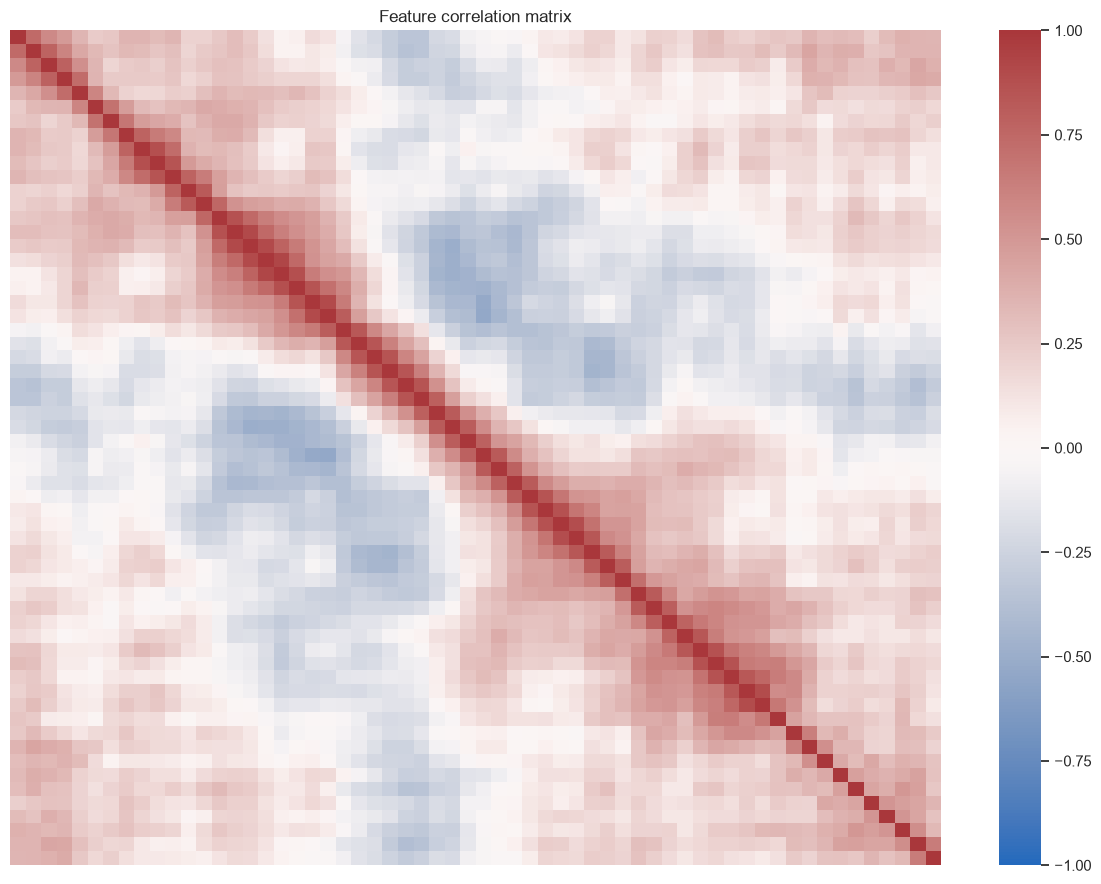

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=y.map(class_names), order=["Rock", "Mine"], ax=axes[0], hue=y.map(class_names), legend=False)
axes[0].set(title="Class counts", xlabel="Target", ylabel="Observations")
for label, color in [(0, "#2878B5"), (1, "#D9534F")]:
    axes[1].plot(X.columns, X[y == label].mean(), label=class_names[label], color=color)
axes[1].set(title="Mean signal by frequency band", xlabel="Feature", ylabel="Mean intensity")
axes[1].tick_params(axis="x", labelbottom=False)
axes[1].legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 9))
sns.heatmap(X.corr(), cmap="vlag", center=0, vmin=-1, vmax=1, xticklabels=False, yticklabels=False)
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.show()


## 3. Hold out an untouched test set

The split is stratified to preserve class proportions. Scaling is placed inside each model pipeline so every cross-validation fold learns its scaler using only that fold’s training partition.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}; test: {X_test.shape}")
print("Training class fractions:", y_train.value_counts(normalize=True).sort_index().round(3).to_dict())


Train: (166, 60); test: (42, 60)
Training class fractions: {0: 0.464, 1: 0.536}


## 4. Cross-validated model selection

Compare a majority-class reference, a scaled RBF SVC, and tree ensembles. Select by **ROC AUC** using repeated stratified folds; use average precision and balanced accuracy as companion metrics. The test set remains unused here.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
}

baseline = DummyClassifier(strategy="most_frequent")
baseline_scores = cross_validate(baseline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

svc_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(class_weight="balanced")),
])
svc_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"],
}
search = GridSearchCV(
    svc_pipe, svc_grid, scoring=scoring, refit="roc_auc",
    cv=cv, n_jobs=-1, return_train_score=True,
)
search.fit(X_train, y_train)

tree_models = {
    "Random forest": RandomForestClassifier(n_estimators=500, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Extra trees": ExtraTreesClassifier(n_estimators=500, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
}
rows = [{"model": "Majority baseline", "ROC AUC": np.nan,
         "Average precision": baseline_scores["test_average_precision"].mean(),
         "Balanced accuracy": baseline_scores["test_balanced_accuracy"].mean()}]
rows.append({"model": "Tuned SVC", "ROC AUC": search.best_score_,
             "Average precision": search.cv_results_["mean_test_average_precision"][search.best_index_],
             "Balanced accuracy": search.cv_results_["mean_test_balanced_accuracy"][search.best_index_]})
for name, estimator in tree_models.items():
    scores = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, "ROC AUC": scores["test_roc_auc"].mean(),
                 "Average precision": scores["test_average_precision"].mean(),
                 "Balanced accuracy": scores["test_balanced_accuracy"].mean()})

cv_results = pd.DataFrame(rows).set_index("model").sort_values("ROC AUC", ascending=False, na_position="last")
display(cv_results.round(3))
print("Best SVC parameters:", search.best_params_)
print(f"Best mean CV ROC AUC: {search.best_score_:.3f}")


,ROC AUC,Average precision,Balanced accuracy
model,,,
Extra trees,0.932,0.946,0.839
Random forest,0.911,0.936,0.765
Tuned SVC,0.911,0.925,0.701
Majority baseline,NaN,0.536,0.500


Best SVC parameters: {'model__C': 1, 'model__gamma': 0.1, 'model__kernel': 'rbf'}
Best mean CV ROC AUC: 0.911


## 5. Final held-out evaluation

Choose the best cross-validated candidate from the training data, refit it on all training rows, and evaluate the test set once. The default decision threshold is 0.5 for probability models; for SVC, the standard decision boundary is used.

Selected model: Extra trees


,test score
Accuracy,0.905
Balanced accuracy,0.902
Precision (Mine),0.875
Recall (Mine),0.955
F1 (Mine),0.913
ROC AUC,0.974
Average precision,0.977


              precision    recall  f1-score   support

        Rock       0.94      0.85      0.89        20
        Mine       0.88      0.95      0.91        22

    accuracy                           0.90        42
   macro avg       0.91      0.90      0.90        42
weighted avg       0.91      0.90      0.90        42



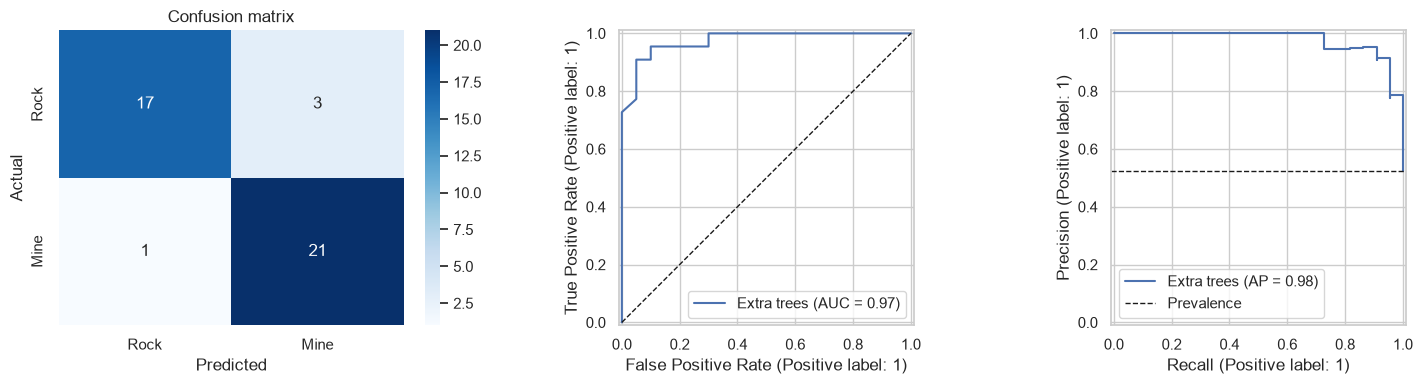

In [6]:
candidate_estimators = {"Tuned SVC": search.best_estimator_, **tree_models}
best_name = cv_results.dropna(subset=["ROC AUC"]).index[0]
final_model = clone(candidate_estimators[best_name]).fit(X_train, y_train)

if hasattr(final_model, "predict_proba"):
    y_score = final_model.predict_proba(X_test)[:, 1]
    y_pred = (y_score >= 0.5).astype(int)
else:
    y_score = final_model.decision_function(X_test)
    y_pred = final_model.predict(X_test)

test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision (Mine)": precision_score(y_test, y_pred, zero_division=0),
    "Recall (Mine)": recall_score(y_test, y_pred, zero_division=0),
    "F1 (Mine)": f1_score(y_test, y_pred, zero_division=0),
    "ROC AUC": roc_auc_score(y_test, y_score),
    "Average precision": average_precision_score(y_test, y_score),
}, name=best_name)
print("Selected model:", best_name)
display(test_metrics.to_frame("test score").round(3))
print(classification_report(y_test, y_pred, target_names=["Rock", "Mine"], zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Rock", "Mine"], yticklabels=["Rock", "Mine"], ax=axes[0])
axes[0].set(title="Confusion matrix", xlabel="Predicted", ylabel="Actual")
RocCurveDisplay.from_predictions(y_test, y_score, ax=axes[1], name=best_name)
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
PrecisionRecallDisplay.from_predictions(y_test, y_score, ax=axes[2], name=best_name)
axes[2].axhline(y_test.mean(), color="k", linestyle="--", lw=1, label="Prevalence")
axes[2].legend()
plt.tight_layout()
plt.show()


## 6. Threshold trade-offs

A classifier threshold should reflect the relative cost of missed mines and false alarms. The curve below describes trade-offs on the held-out data; do **not** choose and report a threshold from this same test set as an unbiased final result. For deployment, choose the threshold within training data using cross-validation and confirm it on a new external test set.

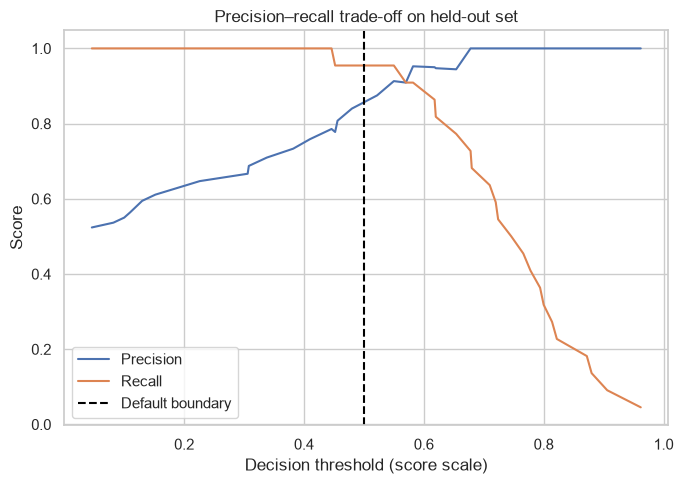

In [7]:
precision, recall, thresholds = precision_recall_curve(y_test, y_score)
plt.figure(figsize=(7, 5))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.axvline(0.5 if hasattr(final_model, "predict_proba") else 0, color="black", linestyle="--", label="Default boundary")
plt.xlabel("Decision threshold (score scale)")
plt.ylabel("Score")
plt.title("Precision–recall trade-off on held-out set")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Interpret feature influence

Permutation importance measures the drop in ROC AUC when one feature is shuffled, evaluated on held-out examples. Correlated bands can share importance, so a low individual score does not prove a feature is irrelevant.

,mean AUC drop,std
band_12,0.0080,0.0056
band_37,0.0056,0.0040
band_27,0.0050,0.0029
band_16,0.0045,0.0033
band_31,0.0039,0.0035
band_36,0.0039,0.0049
band_17,0.0037,0.0031
band_45,0.0028,0.0041
band_28,0.0027,0.0021
band_15,0.0021,0.0021


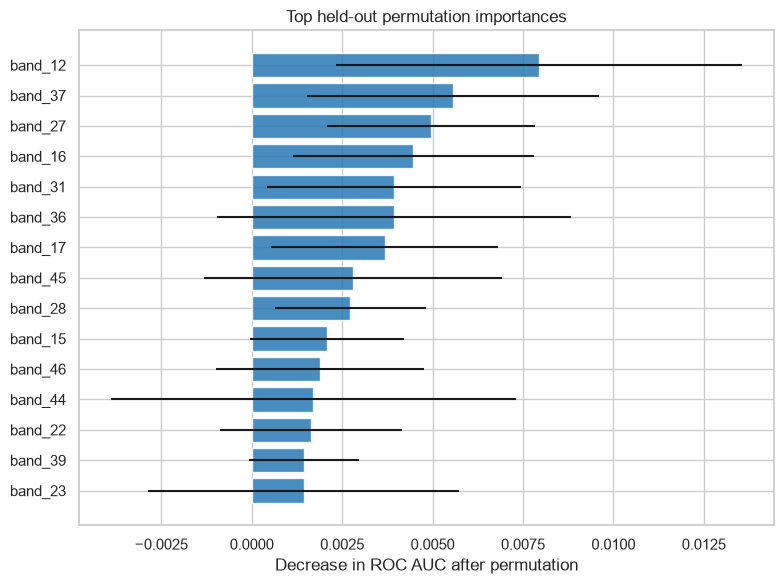

In [8]:
perm = permutation_importance(
    final_model, X_test, y_test, scoring="roc_auc",
    n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1,
)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
importance_std = pd.Series(perm.importances_std, index=X.columns).loc[importance.index]
display(pd.DataFrame({"mean AUC drop": importance.head(15), "std": importance_std.head(15)}).round(4))

top = importance.head(15).sort_values()
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, xerr=importance_std.loc[top.index], color="#2878B5", alpha=0.85)
plt.xlabel("Decrease in ROC AUC after permutation")
plt.title("Top held-out permutation importances")
plt.tight_layout()
plt.show()


## 8. Predict a new observation

Pass exactly 60 feature values in the original band order. The helper returns the predicted class and, when available, a model score. Scores are not necessarily calibrated probabilities unless explicitly calibrated.

In [9]:
def predict_observation(values):
    """Predict rock/mine for one observation containing 60 ordered features."""
    values = np.asarray(values, dtype=float)
    if values.shape != (X.shape[1],):
        raise ValueError(f"Expected {X.shape[1]} feature values; received shape {values.shape}")
    row = pd.DataFrame([values], columns=X.columns)
    prediction = int(final_model.predict(row)[0])
    result = {"prediction": class_names[prediction]}
    if hasattr(final_model, "predict_proba"):
        result["mine_score"] = float(final_model.predict_proba(row)[0, 1])
        result["score_type"] = "estimated probability"
    else:
        result["mine_score"] = float(final_model.decision_function(row)[0])
        result["score_type"] = "decision score"
    return result

sample = X_test.iloc[0]
print("Actual:", class_names[int(y_test.iloc[0])])
print("Prediction:", predict_observation(sample.to_numpy()))


Actual: Mine
Prediction: {'prediction': 'Rock', 'mine_score': 0.446, 'score_type': 'estimated probability'}


## Conclusions and limitations

- Cross-validation selected the model using training data; the held-out metrics estimate performance on similar observations.
- With only 208 measurements, one split can produce noisy results. Report uncertainty and validate on independent data before operational use.
- Sonar bands may be correlated, and permutation importance can distribute their influence across related features.
- Choose an operating threshold from the real costs of missed detections and false alarms, then validate it on fresh data.